<a href="https://colab.research.google.com/github/salimkhaskhoussy/Algorithms-Sorting/blob/main/Reconnaissance_Chiffres_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Reconnaissance de Chiffres Manuscrits avec un modèle CNN (PyTorch)

Nous allons charger les données MNIST à partir des fichiers CSV, les normaliser, puis entraîner un réseau de neurones convolutif (CNN) pour classifier les chiffres de 0 à 9.

In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

# Configuration de l'appareil (GPU si disponible, sinon CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Utilisation de l'appareil : {device}")

Utilisation de l'appareil : cpu


### 1. Chargement et Préparation des Données

In [7]:
# Chargement des fichiers CSV en ignorant la ligne d'en-tête (header=0 par défaut)
train_df = pd.read_csv('/content/mnist_train.csv')
test_df = pd.read_csv('/content/mnist_test.csv')

# Séparation des étiquettes (labels) et des pixels
y_train_raw = train_df.iloc[:, 0].values.astype(np.int64)
X_train_raw = train_df.iloc[:, 1:].values.astype(np.float32)

y_test_raw = test_df.iloc[:, 0].values.astype(np.int64)
X_test_raw = test_df.iloc[:, 1:].values.astype(np.float32)

# Normalisation (0-255 -> 0.0-1.0) et redimensionnement au format (N, Canaux, Hauteur, Largeur)
X_train_reshaped = X_train_raw.reshape(-1, 1, 28, 28) / 255.0
X_test_reshaped = X_test_raw.reshape(-1, 1, 28, 28) / 255.0

# Conversion en tenseurs PyTorch
X_train_tensor = torch.tensor(X_train_reshaped, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_raw, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_reshaped, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_raw, dtype=torch.long)

# Création des DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Données d'entraînement : {X_train_tensor.shape}")
print(f"Données de test : {X_test_tensor.shape}")

Données d'entraînement : torch.Size([60000, 1, 28, 28])
Données de test : torch.Size([10000, 1, 28, 28])


### 2. Définition du Modèle CNN

In [5]:
class MNISTCNN(nn.Module):
    def __init__(self):
        super(MNISTCNN, self).__init__()
        # Première couche de convolution
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Deuxième couche de convolution
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Couches Fully Connected (linéaires)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7) # Aplatir l'image
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

model = MNISTCNN().to(device)
print(model)

MNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [8]:
# S'assurer que les DataLoaders sont bien créés avec les tenseurs existants
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Réinitialisation de l'optimiseur et du critère
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Entraînement du modèle
epochs = 5
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Époque [{epoch+1}/{epochs}] - Perte (Loss) : {epoch_loss:.4f}")

# Évaluation finale sur l'ensemble de test
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"\nPrécision finale sur le jeu de test : {accuracy:.2f}%")

Époque [1/5] - Perte (Loss) : 0.1702
Époque [2/5] - Perte (Loss) : 0.0494
Époque [3/5] - Perte (Loss) : 0.0327
Époque [4/5] - Perte (Loss) : 0.0247
Époque [5/5] - Perte (Loss) : 0.0194

Précision finale sur le jeu de test : 98.95%


### 4. Visualisation de quelques prédictions du modèle

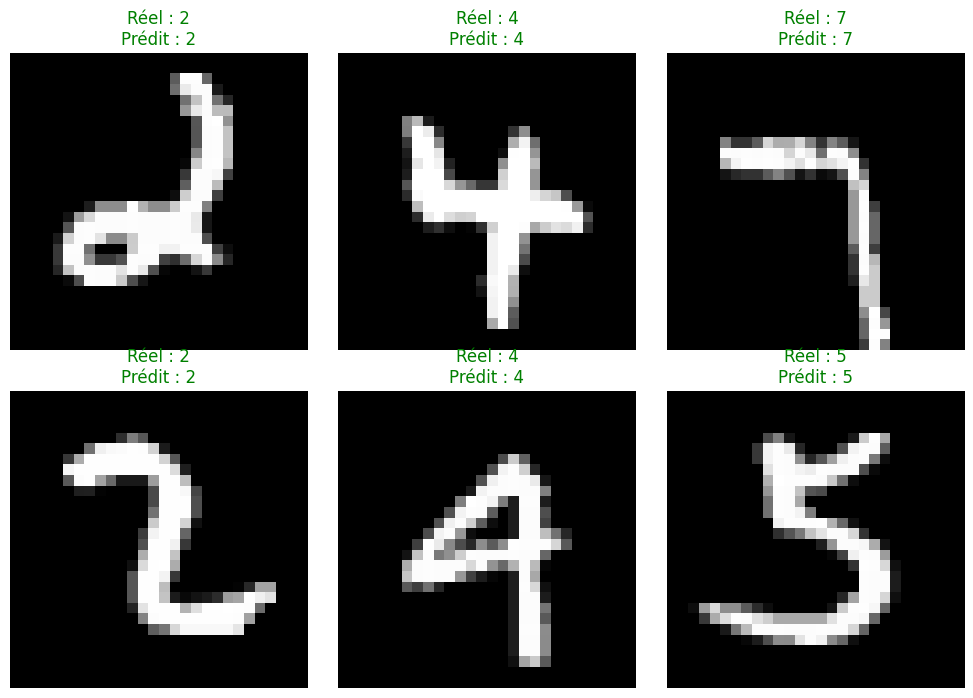

In [9]:
import random

# Passer le modèle en mode évaluation
model.eval()

# Sélectionner quelques indices aléatoires du jeu de test
indices = random.sample(range(len(X_test_tensor)), 6)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
axes = axes.ravel()

for i, idx in enumerate(indices):
    # Obtenir l'image et son étiquette réelle
    image = X_test_tensor[idx]
    true_label = y_test_tensor[idx].item()

    # Prédiction avec le modèle (on ajoute une dimension batch_size=1 pour l'inférence)
    with torch.no_grad():
        input_image = image.unsqueeze(0).to(device)
        output = model(input_image)
        pred_label = torch.argmax(output, dim=1).item()

    # Affichage de l'image
    img_numpy = image.squeeze().numpy() # Repasser en 2D (28, 28) pour affichage
    axes[i].imshow(img_numpy, cmap='gray')

    # Titre en vert si correct, rouge si incorrect
    color = 'green' if pred_label == true_label else 'red'
    axes[i].set_title(f"Réel : {true_label}\nPrédit : {pred_label}", color=color, fontsize=12)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### 5. Visualisation des courbes d'apprentissage (Loss & Accuracy)

Époque [1/5] - Perte : 0.1820 | Précision Test : 98.25%
Époque [2/5] - Perte : 0.0522 | Précision Test : 98.83%
Époque [3/5] - Perte : 0.0354 | Précision Test : 98.96%
Époque [4/5] - Perte : 0.0271 | Précision Test : 98.89%
Époque [5/5] - Perte : 0.0208 | Précision Test : 98.89%


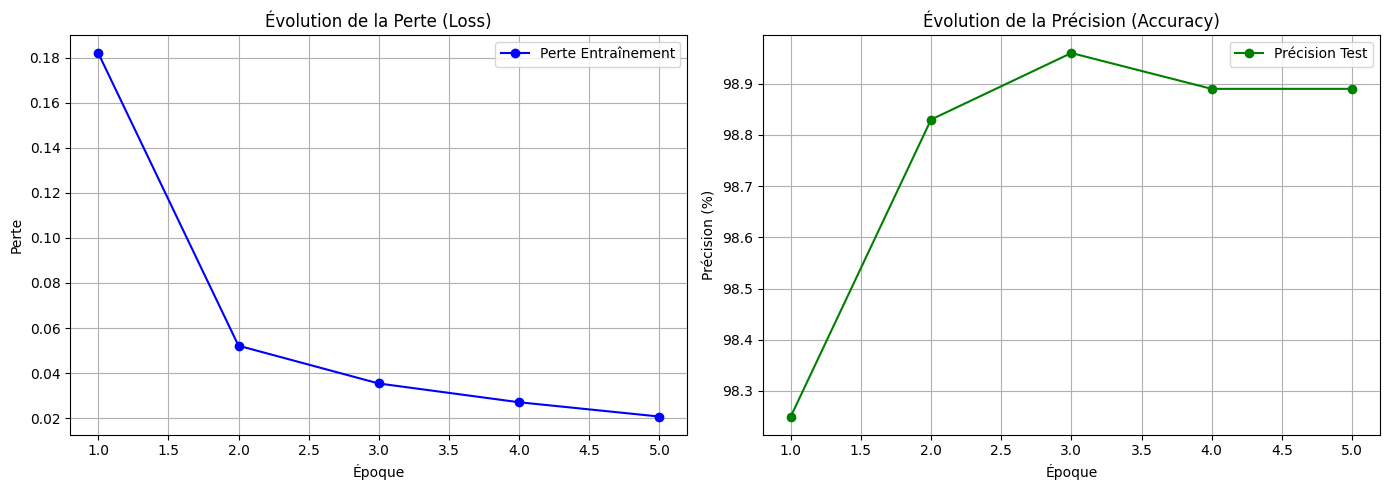

In [10]:
# Réinitialiser le modèle pour un entraînement propre avec suivi des métriques
model = MNISTCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Listes pour stocker les métriques
history_train_loss = []
history_test_acc = []

epochs = 5
for epoch in range(epochs):
    # Entraînement
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    history_train_loss.append(epoch_loss)

    # Évaluation (Précision sur le jeu de test)
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_acc = 100 * correct / total
    history_test_acc.append(epoch_acc)

    print(f"Époque [{epoch+1}/{epochs}] - Perte : {epoch_loss:.4f} | Précision Test : {epoch_acc:.2f}%")

# Tracé des courbes
epochs_range = range(1, epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Courbe de perte (Loss)
ax1.plot(epochs_range, history_train_loss, marker='o', color='blue', label='Perte Entraînement')
ax1.set_title("Évolution de la Perte (Loss)")
ax1.set_xlabel("Époque")
ax1.set_ylabel("Perte")
ax1.grid(True)
ax1.legend()

# Courbe de précision (Accuracy)
ax2.plot(epochs_range, history_test_acc, marker='o', color='green', label='Précision Test')
ax2.set_title("Évolution de la Précision (Accuracy)")
ax2.set_xlabel("Époque")
ax2.set_ylabel("Précision (%)")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()